## Homework 2 - Phase I & II Analysis Using CUSUM and EWMA Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 10, 2026 via D2L**

## Instructions: 

Buster's Sports Bar & Grill runs a busy draft beer program, pouring a house lager through a long-draw, CO2-driven tap system. State regulations require that a pint be poured within a fairly tight volume tolerance, and management has its own reasons to care about consistency too: an overpour on every pint adds up to real lost profit over a month, while a noticeable underpour draws customer complaints and bad reviews. The general manager has asked your quality control team to investigate the pour consistency at the bar's main tap station.

Pours are measured directly from the tap using a calibrated in-line flow meter, in ounces. The general manager has flagged a specific concern: as a CO2 regulator ages, line pressure can creep downward very gradually over weeks or months, producing more foam and a slightly smaller liquid pour -- a small, **sustained** drift, rather than a sudden jump. A chart that's only good at catching a sudden shift could easily miss this kind of slow creep until it's been happening for a long time. Pour volume is treated as a continuous, normally-distributed quality characteristic for this assignment.

Your team pulls a baseline (Phase I) sample of pour data from the tap right after a fresh regulator was installed: 5 pints sampled at random each shift, for 25 consecutive shifts. After validating statistical control, the team designs an appropriate CUSUM and EWMA monitoring scheme and applies it to 20 additional shifts of data (Phase II), collected several months later, to determine whether the aging regulator is already producing a detectable drift.

## Key Specifications

| Quantity | Value |
|---|---|
| Target pour volume | 16.00 oz |
| Lower Specification Limit (LSL) | 15.80 oz |
| Upper Specification Limit (USL) | 16.20 oz |
| Subgroup size (n) | 5 pints per shift |
| Phase I subgroups (m) | 25 shifts |
| Phase II subgroups (m) | 20 shifts |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The purpose of this analysis is to monitor and ensure the consistency of pint pours at Buster's Sports Bar & Grill, specifically focusing on detecting any gradual drift in pour volume that may occur due to the aging CO2 regulator. By using CUSUM and EWMA control charts, the team aims to identify any sustained deviations from the target pour volume, which could lead to customer dissatisfaction and financial losses.

### Q2: Identify the quality characteristic your team will monitor, and classify its units and measurement scale.

The quality characteristic being monitored is the pour volume of beer, measured in ounces. The units are continuous and the measurement scale is ratio, as it has a true zero point (0 ounces).

### Q3: Briefly describe why a CUSUM and EWMA chart would be appropriate in this scenario, given the general manager's specific concern about the aging CO2 regulator. What are the limitations of these charts?

CUSUM and EWMA charts are particularly useful for detecting small, sustained shifts in the process mean, which is exactly what the general manager is concerned about with the aging CO2 regulator. These charts are more sensitive to small changes than traditional Shewhart control charts, making them ideal for monitoring gradual drifts in pour volume.

However, both CUSUM and EWMA charts have limitations. They require more complex calculations and setup compared to Shewhart $\bar{X}$ charts. Additionally, they may be less intuitive for operators to interpret and act upon, potentially leading to slower response times to actual process changes.

## Analyze

### Q4: Read the Phase I data into R. Calculate and report the subgroup means and ranges, and use them to estimate the process mean and process standard deviation.

In [1]:
## Q4 Code ##

library(tidyverse)
library(readxl)
library(qcc)

## Set Working Directory ##

setwd('d:\\KSU\\Teaching\\STAT 7110\\STAT-7110-Quality-Control\\Assignments\\HW2')

## Read in Data ##

p1 <- read_excel("BustersSportsBar_PhaseI.xlsx")

p1 |>
  glimpse()

## Calculate Subgroup Means and Ranges ##

p1_df <- p1 |>
  mutate(Mean = rowMeans(pick(starts_with("Pour"))),
         Range = apply(pick(starts_with("Pour")), 1, function(x) max(x) - min(x)))

print(p1_df)

## Calculate Process Mean and Standard Deviation ##

xdbar <- mean(p1_df$Mean)
rbar <- mean(p1_df$Range)
sig_hat <- rbar / 2.326  # d2 for n=5 is approximately 2.326

cat("Estimated Process Mean (xdbar): ", xdbar, "\n")
cat("Estimated Process Range (rbar): ", rbar, "\n")
cat("Estimated Process Standard Deviation (sig_hat): ", sig_hat, "\n")


── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the ]8;;http://conflicted.r-lib.org/conflicted package]8;; to force all conflicts to become errors
  __ _  ___ ___ 
 / _  |/ __/ __|  Quality Control Charts and 
| (_| | (_| (__   Statistical Process Control
 \__  |\___\___|
    |_|           version 2.7
Type 'citation("qcc")' for citing this R package in publications.
Rows: 25
Columns: 6
$ Shift <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25
$ Pour1 <dbl> 16.0413, 16.0675, 16.0556, 16

### Q5: Construct a Phase I $R$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.

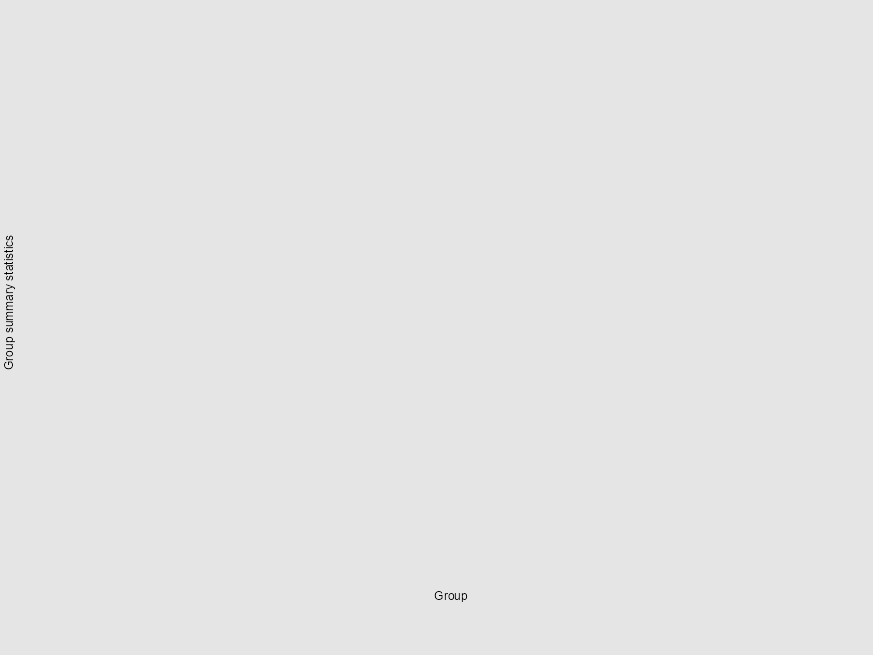

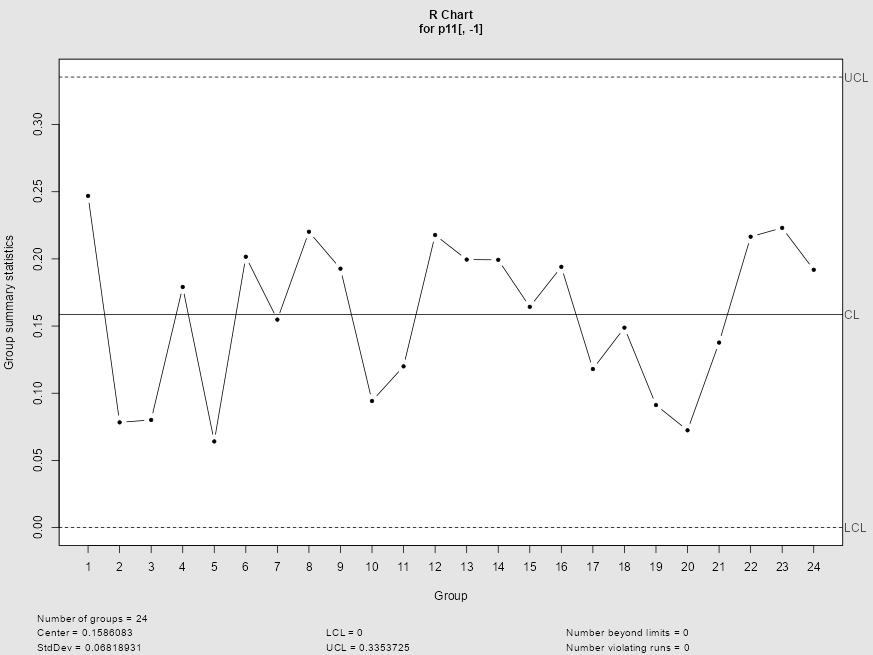

In [2]:
## Q5 Code ##

p1r <- qcc(p1[,-1],type="R",plot=T)

## Identify OOC point, omit, and replot ##

p11 <- p1[-p1r$violations$beyond.limits,]

p11r <- qcc(p11[,-1],type="R",plot=T)

Here, we can see that the Phase I $R$ chart does not show evidence of statistical control since there is an OOC point at Shift 19. This could be due to a temporary issue, such as a dirty tap or a momentary fluctuation in CO2 pressure. After omitting this point and replotting the chart, we can observe that the remaining subgroups are in statistical control.

### Q6: Using only the subgroups retained after Q5, construct the Phase I $\bar{X}$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.

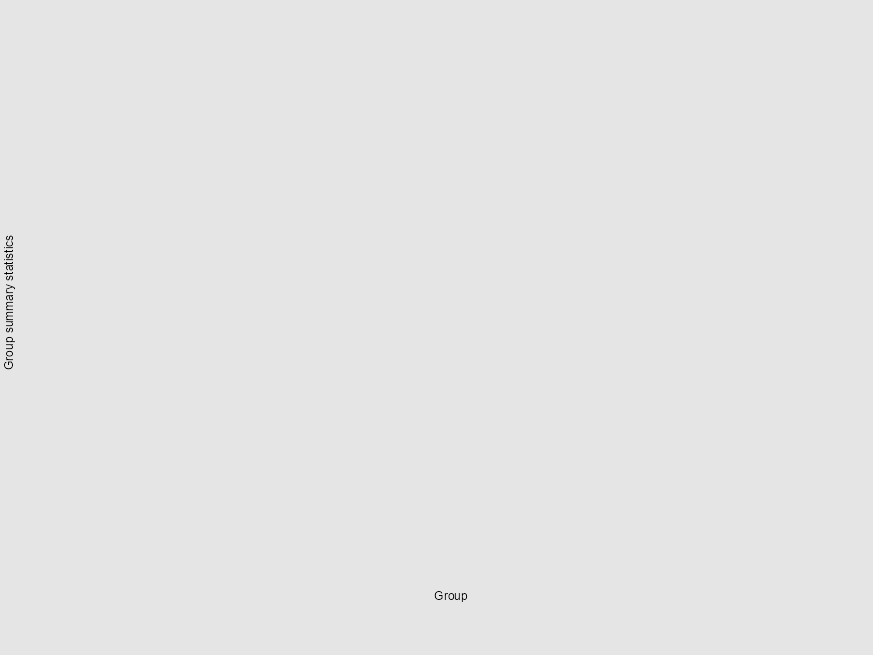

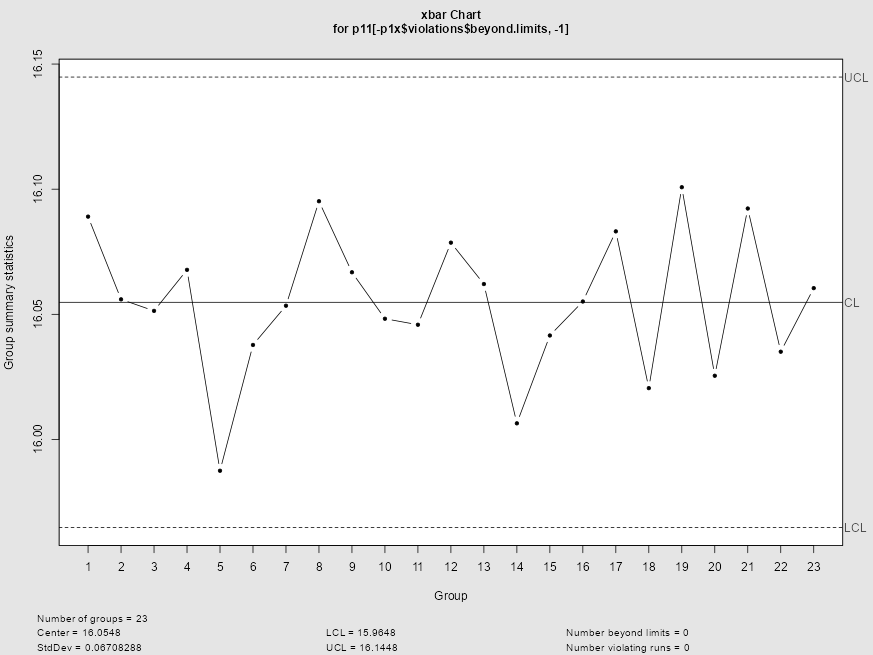

In [3]:
## Q6 Code ##

p1x <- qcc(p11[,-1],type="xbar",plot=T)

## Omit OOC points and replot until statistical control is observed ##

p11x <- qcc(p11[-p1x$violations$beyond.limits, -1], type="xbar", plot=T)

Using the data retained after establishing statistical control in Q5, we constructed an initial Phase I $\bar{X}$ chart. The chart indicated that there was an OOC point at Shift 12. Since this point fell below the LCL, a potential assignable cause could be also related to the dirty tap or a temporary fluctuation in CO2 pressure. After omitting this point and replotting the chart, we observed that the remaining subgroups were in statistical control.

### Q7: Using your final Phase I estimates of the process mean and process standard deviation, perform a process capability analysis against the specification limits given above. Report and interpret $FNC$, $C_p$, $C_{pk}$, and $C_{pm}$. Is the process capable of meeting specification? Is it well-centered?

In [4]:
print(p11x$limits)

     LCL     UCL
 15.9648 16.1448


In [6]:
## Q7 Code ##

## Calculate FNC ##

USL <- 16.20
LSL <- 15.80
target <- 16.00

fnc <- pnorm(USL,mean=p11x$center,sd=p11x$std.dev,lower.tail=F) + 
  pnorm(LSL,mean=p11x$center,sd=p11x$std.dev,lower.tail=T)

## Calculate Cp ##

cp <- (USL - LSL) / (6 * p11x$std.dev)

## Cpk ##

cpu <- (USL - p11x$center) / (3 * p11x$std.dev)
cpl <- (p11x$center - LSL) / (3 * p11x$std.dev)

cpk <- min(cpu,cpl)

## Cpm ##

cpm <- (USL - LSL) / (6 * sqrt(p11x$std.dev^2 + (p11x$center - target)^2))

## Report ##

cat("FNC: ", fnc, "\n")
cat("Cp: ", cp, "\n")
cat("Cpu: ", cpu, "\n")
cat("Cpl: ", cpl, "\n")
cat("Cpk: ", cpk, "\n")
cat("Cpm: ", cpm, "\n")

FNC:  0.01528784 
Cp:  0.9937955 
Cpu:  0.7214826 
Cpl:  1.266108 
Cpk:  0.7214826 
Cpm:  0.7696239 


An FNC of 1.529% tells us that approximately 1.5 out of every hundred beers poured are expected to fall outside the specification limits. The $C_p$ value of 0.9938 indicates that the process is not quite capable of meeting specification as the specification bandwidth is slightly narrower than the process spread. The $C_{pk}$ value of 0.72, which is associated with $C_{pu}$, indicates that the process is not well-centered and is skewed toward the USL. The value of 0.72 itself is well below 1. Contextually, this means we are more likely to see an out-of-spec pour on the high side than on the low side. The $C_{pm}$ value of 0.76 indicates that the process is not capable of meeting specification when considering the target value, and it is not well-centered around the target.

## Improve

### Q8: The general manager wants a monitoring scheme that reliably detects a sustained shift of about one process standard deviation (representing early-stage regulator drift) while keeping the in-control ARL around 370-500. Using the design guidance from lecture, select and briefly justify: (a) the CUSUM slack value $K$ and decision interval $H$, and (b) the EWMA smoothing constant $\lambda$ and width $L$, that you will carry forward into your Phase II monitoring plan.

- For CUSUM, we will use a slack value of $K = 0.5$ and a decision interval of $H = 5$. This choice has been shown to yield $ARL_0$ of around 465, which is within the desired range. This choice also provides a reasonable detection time for a $1\sigma$ shift, with an estimated $ARL_1$ of approximately 10, which is acceptable for the general manager's concern about early-stage regulator drift.

- For EWMA, we will use $\lambda = 0.20$ and $L=2.962$ as these values have been shown to yield $ARL_0$ of exactly 500, which is within the desired range. Additionally, for a $1\sigma$ shift, the estimated $ARL_1$ is also approximately 10.

## Control

### Q9: Read the Phase II data into R. Using your final Phase I estimates from Q6 and the CUSUM parameters you selected in Q8, construct the Phase II CUSUM chart. Does the chart signal an out-of-control condition? If so, at which shift number?

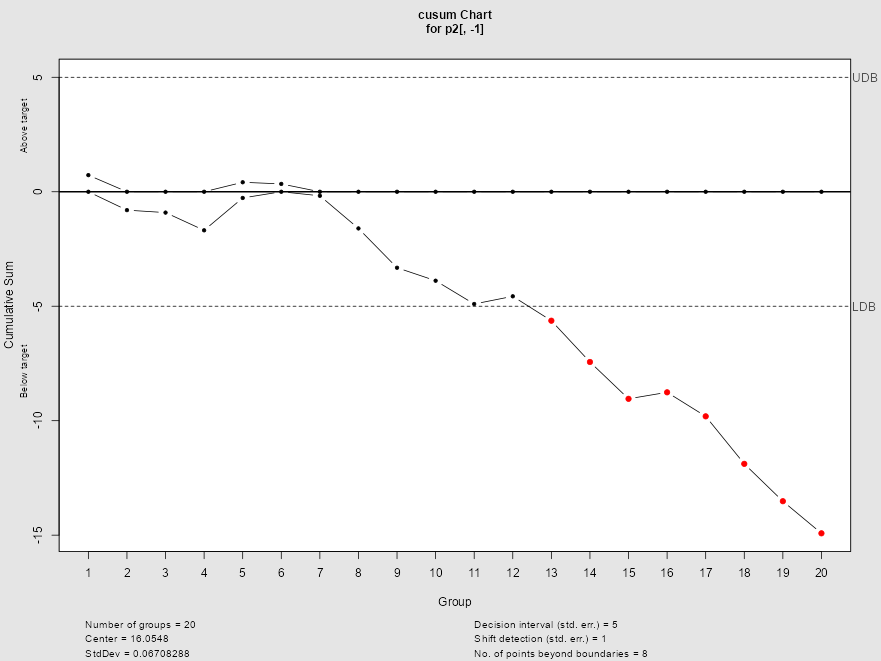

In [18]:
## Q9 Code ##

p2 <- read_excel("BustersSportsBar_PhaseII.xlsx")

p2_cusum <- cusum(p2[,-1], sizes=5, center=p11x$center, std.dev=p11x$std.dev, 
                 decision.interval=5, se.shift=0.5*2, plot=T)

Using the CUSUM chart, we observed that the chart signaled OOC at shift 15 in the lower direction. This implies that the process mean has shifted downward, which could be indicative of the aging CO2 regulator causing a sustained decrease in pour volume. However, since our process center is already above the target, this downward shift may not be as concerning as an upward shift would be. Nonetheless, it is important to investigate the cause of this shift to ensure that the process remains within acceptable limits.

### Q10: Using your final Phase I estimates from Q6 and the EWMA parameters you selected in Q8, construct the Phase II EWMA chart. Does the chart signal an out-of-control condition? If so, at which shift number?

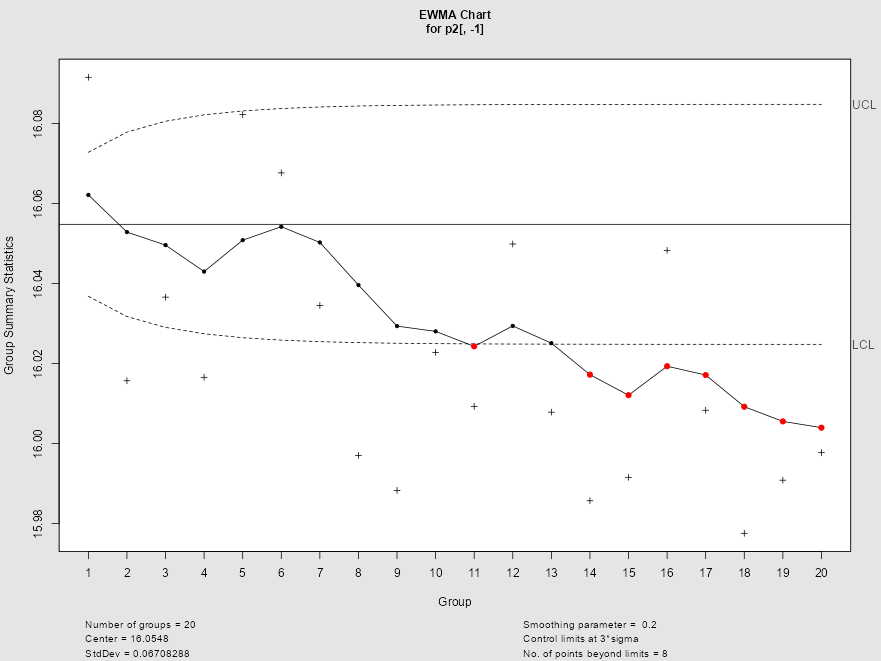

In [19]:
## Q10 Code ##

p2_ewma <- ewma(p2[,-1], sizes=5, center=p11x$center, std.dev=p11x$std.dev, 
                 lambda=0.20, L=2.962, plot=T)

Here, the EWMA chart also signaled an out-of-control condition but now at shift 11, indicating a downward shift in the process mean. This is consistent with the CUSUM chart's findings, confirming that both monitoring schemes detected the same sustained shift in pour volume. Here, since EWMA is in the original units of the process, we can see that the process mean is shifting back closer to the target, but it is still slightly above the target. 

### Q11: Compare the results of Q9 and Q10. Which chart detected the shift more quickly, if either? Is this consistent with what you would expect, given what you know about the relative sensitivity of CUSUM and EWMA charts to small, sustained shifts? Briefly explain.

The EWMA chart detected the shift more quickly than the CUSUM chart, signaling OOC at shift 11 compared to shift 15 for the CUSUM chart. The EWMA chart can be more intuitively tuned to detect specific shifts whereas it is not quite as obvious for CUSUM. In general, though, the choices of parameters for both charts were made to yield similar detection times for a $1\sigma$ shift, and that's generally what we observed here.

### Q12: Provide an overview of the results that the general manager can provide to Buster's ownership. Does the CO2 regulator need to be replaced ahead of schedule, or can it run as planned?

The results of the Phase I and Phase II analysis indicate that the pour volume process is exhibiting inconsistent variation. In Phase I, we observed that the process tended to be on the high side of the target, with about 1 out of every 100 pints expected to be out of specification. In Phase II, we detected a downward shift in the process mean, which is consistent with the general manager's concern about the aging CO2 regulator. These inconsistencies suggest that the CO2 regulator may be contributing to the observed drift in pour volume. Given these findings, it would be prudent for Buster's ownership to consider replacing the CO2 regulator ahead of schedule to ensure that the pour volume remains within acceptable limits and to maintain customer satisfaction.